# 02 — Local dynamics
For neighbor sum $k$, the heat-bath plus probability is $(1+e^{-2\beta(k+h)})^{-1}$. Metropolis accepts a flip with probability $\min(1,e^{-2\beta s(k+h)})$. Here we independently calculate one update, then compare with the production kernel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from ising import IsingModel, Simulator
import ising.kernels.local as kernels
import ising.observables as obs
from ising.state import make_state
import inspect

In [2]:
model = IsingModel(N=5, beta=.55, lam=2.)
k_values = np.arange(-4, 5, 2)
heatbath_probs, metropolis_probs = kernels.local_tables(model)
expected_heatbath_probs = 1/(1+np.exp(-2*model.beta*(k_values+model.h)))
expected_metropolis_probs = np.minimum(1, np.exp(-2*model.beta*np.array([-1,1])[:,None]*(k_values+model.h)))
np.testing.assert_allclose(heatbath_probs, expected_heatbath_probs)
np.testing.assert_allclose(metropolis_probs, expected_metropolis_probs)
print("k:", k_values, "\nheat bath:", heatbath_probs, "\nMetropolis rows (-,+):\n", metropolis_probs)

k: [-4 -2  0  2  4] 
heat bath: [0.01870651 0.14679034 0.60825903 0.93339196 0.99215498] 
Metropolis rows (-,+):
 [[0.01906311 0.17204486 1.         1.         1.        ]
 [1.         1.         0.64403642 0.07136127 0.00790705]]


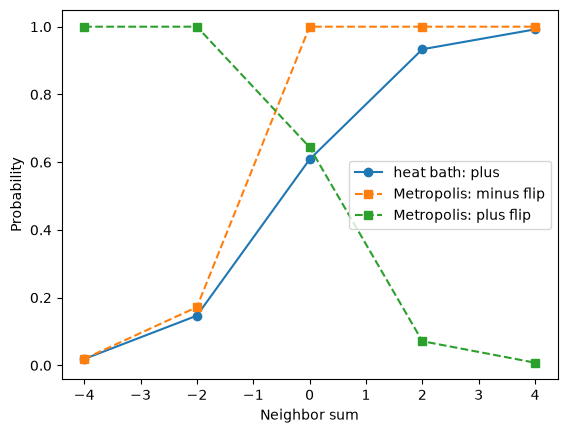

In [3]:
plt.plot(k_values, heatbath_probs, 'o-', label='heat bath: plus')
plt.plot(k_values, metropolis_probs[0], 's--', label='Metropolis: minus flip')
plt.plot(k_values, metropolis_probs[1], 's--', label='Metropolis: plus flip')
plt.xlabel('Neighbor sum'); plt.ylabel('Probability'); plt.legend(); plt.show()

## Inspect a single update
Padded coordinates are one-based for the interior. Flattening a C-contiguous array gives index `row * width + col`. The table column is `(neighbor_sum+4)//2`. Edit the site, uniform or rule.

In [4]:
spins = make_state(model.N, "random", np.random.default_rng(42))
row, col, uniform_draw = 1, 2, .3
use_heatbath = True
padded_width = spins.shape[1]
site = row*padded_width + col
flat_spins = spins.ravel()
neighbors = flat_spins[[site-1, site+1, site-padded_width, site+padded_width]]
neighbor_sum = int(neighbors.sum())
old_spin = int(flat_spins[site])
num_plus_neighbors = (neighbor_sum+4)//2
new_spin = (1 if uniform_draw < heatbath_probs[num_plus_neighbors] else -1) if use_heatbath else (-old_spin if uniform_draw < metropolis_probs[(old_spin+1)//2,num_plus_neighbors] else old_spin)
print(spins, neighbors, neighbor_sum, old_spin, new_spin, sep="\n")

[[-1 -1 -1 -1 -1 -1 -1]
 [-1 -1  1  1 -1 -1 -1]
 [-1  1 -1  1 -1 -1 -1]
 [-1  1  1  1  1  1 -1]
 [-1  1  1 -1  1 -1 -1]
 [-1  1 -1 -1  1  1 -1]
 [-1 -1 -1 -1 -1 -1 -1]]
[-1  1 -1 -1]
-2
1
-1


## Incremental observables
$\Delta M=s'-s$, $\Delta L=(s-s')k/2$, and $\Delta H=-(s'-s)(k+h)$. Here $L$ counts all disagreeing interior-incident edges, not just a droplet exterior.

In [5]:
M = int(spins[1:-1,1:-1].sum())
L = obs.interface_length(spins)
expected = spins.copy(); expected[row,col] = new_spin
M_new = M + new_spin-old_spin
L_new = L + (old_spin-new_spin)*neighbor_sum//2
assert M_new == expected[1:-1,1:-1].sum()
assert L_new == obs.interface_length(expected)
H = obs.thermodynamics(model.N, model.h, M, L)['energy']
H_new = obs.thermodynamics(model.N, model.h, M_new, L_new)['energy']
assert np.isclose(H_new-H, -(new_spin-old_spin)*(neighbor_sum+model.h))

In [6]:
for kernel in (kernels.random_updates_python, kernels.random_updates_numba):
    actual = spins.copy()
    result = kernel(actual.ravel(), padded_width, np.array([site]), np.array([uniform_draw]), heatbath_probs, metropolis_probs, use_heatbath, M, L)
    assert result == (1, M_new, L_new)
    np.testing.assert_array_equal(actual, expected)
print('Both backends reproduce the independently calculated update.')

Both backends reproduce the independently calculated update.


## Sequential random-site attempts
Repeated sites are allowed. Do not vectorize these updates as simultaneous writes: subsequent updates must see earlier changes.

In [7]:
for dynamics in ('heatbath','metropolis'):
    python_sim = Simulator(model, seed=17, init='random', dynamics=dynamics, backend='python')
    numba_sim = Simulator(model, seed=17, init='random', dynamics=dynamics, backend='numba')
    for count in (1, 7, 31, 100):
        python_sim.advance_updates(count); numba_sim.advance_updates(count)
        np.testing.assert_array_equal(python_sim.state,numba_sim.state)
        assert python_sim.observe() == numba_sim.observe()
print('Seeded backend equality verified for both local rules.')

Seeded backend equality verified for both local rules.


In [8]:
print(inspect.getsource(kernels.random_updates_python))

def random_updates_python(flat, w, sites, uniforms, hb, mp, heatbath,
                          spin_sum, length, direction=0, threshold=0.0, area=1):
    """Sequential random-site reference loop; stop at first threshold crossing.

    direction=0 disables stopping; +1 means upward, -1 downward.
    Return number of attempts consumed and updated total spin and broken-bond count.
    """
    for update_idx in range(len(sites)):
        site = sites[update_idx]
        num_plus_neighbors = (int(flat[site-1]) + int(flat[site+1]) + int(flat[site-w])
             + int(flat[site+w]) + 4) // 2
        old_spin = int(flat[site])
        new_spin = old_spin
        if heatbath:
            new_spin = 1 if uniforms[update_idx] < hb[num_plus_neighbors] else -1
        elif uniforms[update_idx] < mp[(old_spin+1)//2, num_plus_neighbors]:
            new_spin = -old_spin
        flat[site] = new_spin
        spin_sum += new_spin - old_spin
        length += ((old_spin-new_spin)//2)*(2*num_plus_neig